# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    root_mean_squared_error, mean_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from xgboost import XGBRegressor
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "data/raw/kc_house_data.csv"
if not os.path.exists(CSV_PATH) and os.path.exists("../data/raw/kc_house_data.csv"):
    CSV_PATH = "../data/raw/kc_house_data.csv"

df_raw = pd.read_csv(CSV_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Raw Dataset Shape: 21,613 rows, 21 columns


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


# EDA 1: Schema, Missing Values & Exact Duplicate Audit (Sebelum Cleaning)

In [2]:
print(f"Exact Full-Row Duplicates        : {df_raw.duplicated().sum()}")
print(f"Unique Property IDs ('id')       : {df_raw['id'].nunique():,} out of {len(df_raw):,} rows ({len(df_raw) - df_raw['id'].nunique()} repeat sales)")

# Verify exact collinearity: sqft_living == sqft_above + sqft_basement
collinear_diff = (df_raw["sqft_living"] - (df_raw["sqft_above"] + df_raw["sqft_basement"])).abs().max()
print(f"Max absolute difference between sqft_living and (sqft_above + sqft_basement): {collinear_diff}")

audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Null_Count": df_raw[col].isnull().sum(),
        "Unique_Values": df_raw[col].nunique(),
        "Min": df_raw[col].min() if df_raw[col].dtype != "object" else str(df_raw[col].min())[:10],
        "Max": df_raw[col].max() if df_raw[col].dtype != "object" else str(df_raw[col].max())[:10],
    })
display(pd.DataFrame(audit_records))

Exact Full-Row Duplicates        : 0
Unique Property IDs ('id')       : 21,436 out of 21,613 rows (177 repeat sales)
Max absolute difference between sqft_living and (sqft_above + sqft_basement): 0


,Column,Dtype,Null_Count,Unique_Values,Min,Max
0,id,int64,0,21436,1000102,9900000190
1,date,str,0,372,20140502T000000,20150527T000000
2,price,float64,0,4028,75000.0,7700000.0
3,bedrooms,int64,0,13,0,33
4,bathrooms,float64,0,30,0.0,8.0
5,sqft_living,int64,0,1038,290,13540
6,sqft_lot,int64,0,9782,520,1651359
7,floors,float64,0,6,1.0,3.5
8,waterfront,int64,0,2,0,1
9,view,int64,0,5,0,4


# EDA 2: Transaction Amount, Time Dynamics & PCA Feature Correlations

Raw Price Skewness : 4.02 | Log(Price) Skewness : 0.43

Anomalous Records with bedrooms > 10 or bedrooms == 0 or bathrooms == 0:
Total anomalous records found: 18


,id,price,bedrooms,bathrooms,sqft_living,floors,grade
15870,2402100895,640000.0,33,1.75,1620,1.0,7
8757,1773100755,520000.0,11,3.00,3000,2.0,7
10481,203100435,484000.0,1,0.00,690,1.0,7
1149,3421079032,75000.0,1,0.00,670,1.0,3
5832,5702500050,280000.0,1,0.00,600,1.0,3
875,6306400140,1095000.0,0,0.00,3064,3.5,7
4868,6896300380,228000.0,0,1.00,390,1.0,4
6994,2954400190,1295650.0,0,0.00,4810,2.0,12
3467,1453602309,288000.0,0,1.50,1430,3.0,7
3119,3918400017,380000.0,0,0.00,1470,3.0,8


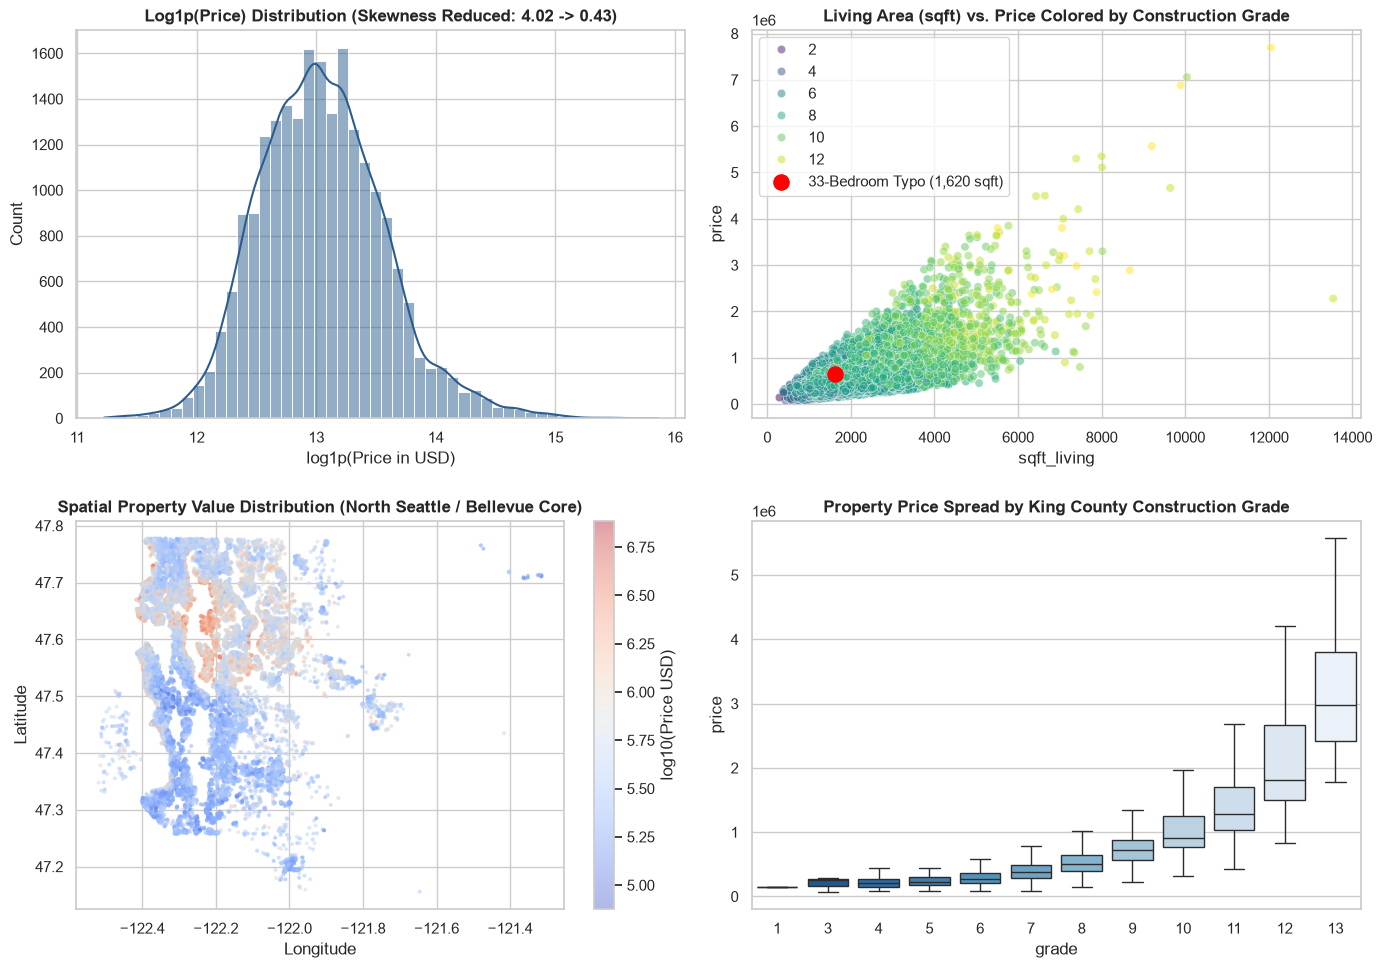

In [3]:
print(f"Raw Price Skewness : {df_raw['price'].skew():.2f} | Log(Price) Skewness : {np.log1p(df_raw['price']).skew():.2f}")

# Inspect extreme bedroom/bathroom anomalies
print("\nAnomalous Records with bedrooms > 10 or bedrooms == 0 or bathrooms == 0:")
anomalies = df_raw[(df_raw["bedrooms"] > 10) | (df_raw["bedrooms"] == 0) | (df_raw["bathrooms"] == 0)]
print(f"Total anomalous records found: {len(anomalies)}")
display(anomalies[["id", "price", "bedrooms", "bathrooms", "sqft_living", "floors", "grade"]].sort_values(by="bedrooms", ascending=False).head(10))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Raw Price vs Log-Transformed Price Distribution
sns.histplot(np.log1p(df_raw["price"]), bins=50, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title(f"Log1p(Price) Distribution (Skewness Reduced: {df_raw['price'].skew():.2f} -> {np.log1p(df_raw['price']).skew():.2f})", fontweight="bold")
axes[0, 0].set_xlabel("log1p(Price in USD)")

# 2. Living Area vs Price (Highlighting the 33-Bedroom Typo)
sns.scatterplot(data=df_raw, x="sqft_living", y="price", hue="grade", palette="viridis", alpha=0.5, ax=axes[0, 1])
typo_row = df_raw[df_raw["bedrooms"] == 33].iloc[0]
axes[0, 1].scatter(typo_row["sqft_living"], typo_row["price"], color="red", s=120, zorder=5, label="33-Bedroom Typo (1,620 sqft)")
axes[0, 1].set_title("Living Area (sqft) vs. Price Colored by Construction Grade", fontweight="bold")
axes[0, 1].legend()

# 3. Spatial Price Heatmap across King County (Latitude vs Longitude)
sc = axes[1, 0].scatter(
    df_raw["long"], df_raw["lat"], c=np.log10(df_raw["price"]),
    cmap="coolwarm", alpha=0.4, s=4
)
plt.colorbar(sc, ax=axes[1, 0], label="log10(Price USD)")
axes[1, 0].set_title("Spatial Property Value Distribution (North Seattle / Bellevue Core)", fontweight="bold")
axes[1, 0].set_xlabel("Longitude")
axes[1, 0].set_ylabel("Latitude")

# 4. Median Price by Building Grade
sns.boxplot(data=df_raw, x="grade", y="price", palette="Blues_r", showfliers=False, ax=axes[1, 1])
axes[1, 1].set_title("Property Price Spread by King County Construction Grade", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_house_valuation.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning (Berdasarkan Temuan EDA)

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Fix the confirmed data entry typo where id=2402100895 has 33 bedrooms in a 1,620 sqft home (correct to 3 bedrooms).
2. Remove 16 incomplete/uninhabitable structure records where bedrooms == 0 or bathrooms == 0.
3. Parse sale 'date' (format 'YYYYMMDDT000000') to extract sale_year and sale_month, then drop raw 'id' and 'date'.
4. Drop 'sqft_above' to eliminate exact linear collinearity (since sqft_living == sqft_above + sqft_basement).
5. Cast 'zipcode' to string so OneHotEncoder treats the 70 postal zones as categorical locations rather than continuous numbers.
"""
df_clean = df_raw.copy()

# 1. Correct the 33-bedroom typo to 3 bedrooms
df_clean.loc[df_clean["bedrooms"] == 33, "bedrooms"] = 3

# 2. Filter out 0-bedroom or 0-bathroom records
df_clean = df_clean[(df_clean["bedrooms"] > 0) & (df_clean["bathrooms"] > 0)].reset_index(drop=True)

# 3. Parse sale date
df_clean["parsed_date"] = pd.to_datetime(df_clean["date"].str.slice(0, 8), format="%Y%m%d")
df_clean["sale_year"] = df_clean["parsed_date"].dt.year
df_clean["sale_month"] = df_clean["parsed_date"].dt.month

# 4. Cast zipcode to categorical string & drop redundant columns
df_clean["zipcode"] = df_clean["zipcode"].astype(str)
df_clean.drop(columns=["id", "date", "parsed_date", "sqft_above"], inplace=True)

print(f"Raw Rows: {len(df_raw):,} -> Cleaned Rows: {len(df_clean):,} | Remaining Columns: {df_clean.shape[1]}")

Raw Rows: 21,613 -> Cleaned Rows: 21,597 | Remaining Columns: 20


# Domain Feature Engineering & Leak-Free Scaling

In [5]:
df_feat = df_clean.copy()

# 1. Property age at the time of sale & renovation recency
df_feat["house_age"] = np.maximum(df_feat["sale_year"] - df_feat["yr_built"], 0)
df_feat["is_renovated"] = (df_feat["yr_renovated"] > 0).astype(int)
effective_year = np.where(df_feat["yr_renovated"] > 0, df_feat["yr_renovated"], df_feat["yr_built"])
df_feat["years_since_update"] = np.maximum(df_feat["sale_year"] - effective_year, 0)

# 2. Living space relative to the 15 nearest neighbors (captures neighborhood-level luxury premium)
df_feat["living_to_neighbor15_ratio"] = df_feat["sqft_living"] / (df_feat["sqft_living15"] + 1.0)
df_feat["lot_utilization_ratio"] = df_feat["sqft_living"] / (df_feat["sqft_lot"] + 1.0)
df_feat["has_basement"] = (df_feat["sqft_basement"] > 0).astype(int)

# 3. Haversine distance (in km) from Downtown Seattle / Bellevue high-value commercial core (47.6205° N, -122.3493° W)
lat1, lon1 = np.radians(df_feat["lat"]), np.radians(df_feat["long"])
lat2, lon2 = np.radians(47.6205), np.radians(-122.3493)
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
df_feat["dist_to_seattle_center_km"] = 6371.0 * (2.0 * np.arcsin(np.sqrt(a)))

X = df_feat.drop(columns=["price"])
y = df_feat["price"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = ["zipcode"]
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

Train Shape: (17277, 26) | Test Shape: (4320, 26)


# Model Benchmarking (Logistic Regression vs. Isolation Forest + XGBoost vs. LightGBM)

In [6]:
models = {
    "Log-Target Ridge Regression (Baseline)": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("model", Ridge(alpha=10.0, random_state=42)),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "Log-Target XGBoost Regressor (AVM Engine)": TransformedTargetRegressor(
        regressor=Pipeline([
            ("preprocessor", preprocessor),
            ("model", XGBRegressor(
                n_estimators=500,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                tree_method="hist",
                n_jobs=-1,
                random_state=42,
            )),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}

best_model, best_rmse = None, float("inf")

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = root_mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    r2 = r2_score(y_test, y_pred)

    print(f"\n---> {name}")
    print(f"RMSE : ${rmse:,.2f} | MAE : ${mae:,.2f} | MAPE : {mape:.2f}% | R² Score : {r2:.4f}")

    if rmse < best_rmse:
        best_rmse = rmse
        best_model = model

joblib.dump(best_model, "outputs/best_house_valuation_model.joblib")


---> Log-Target Ridge Regression (Baseline)
RMSE : $128,241.20 | MAE : $71,987.01 | MAPE : 13.45% | R² Score : 0.8736

---> Log-Target XGBoost Regressor (AVM Engine)
RMSE : $122,781.43 | MAE : $60,040.67 | MAPE : 11.26% | R² Score : 0.8841


['outputs/best_house_valuation_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

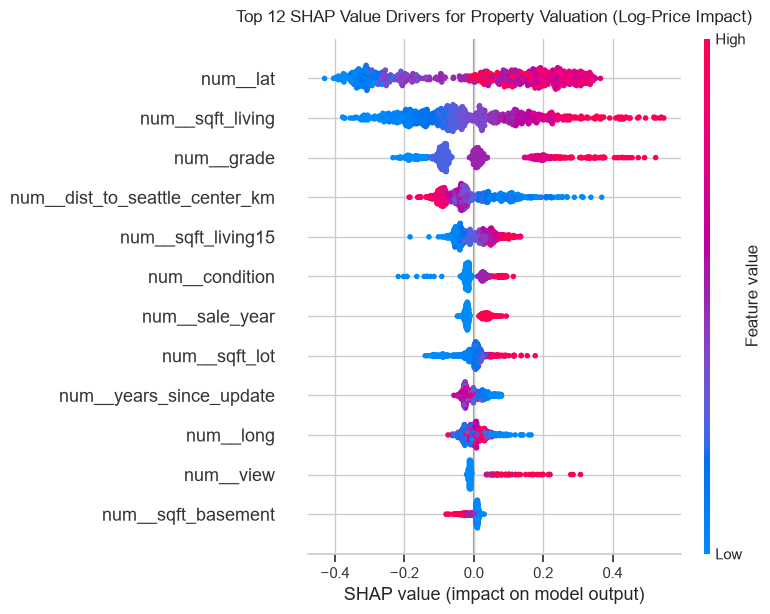

In [7]:
xgb_fitted_pipe = models["Log-Target XGBoost Regressor (AVM Engine)"].regressor_

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = xgb_fitted_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = xgb_fitted_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_fitted_pipe.named_steps["model"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Value Drivers for Property Valuation (Log-Price Impact)", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_house_valuation.png", dpi=150)
plt.show()

# Ablation: Raw-Target Ridge vs. Log-Target Ridge

In [8]:
raw_ridge = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0, random_state=42)),
])
raw_ridge.fit(X_train, y_train)
y_pred_raw = raw_ridge.predict(X_test)
y_pred_log = models["Log-Target Ridge Regression (Baseline)"].predict(X_test)

comp_day4 = pd.DataFrame([
    {
        "Variant": "Raw-Target Ridge (No Log Transform)",
        "RMSE ($)": root_mean_squared_error(y_test, y_pred_raw),
        "MAE ($)": mean_absolute_error(y_test, y_pred_raw),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred_raw) * 100,
        "R2": r2_score(y_test, y_pred_raw),
        "Negative_Predictions": int((y_pred_raw < 0).sum()),
    },
    {
        "Variant": "Log-Target Ridge (log1p / expm1)",
        "RMSE ($)": root_mean_squared_error(y_test, y_pred_log),
        "MAE ($)": mean_absolute_error(y_test, y_pred_log),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred_log) * 100,
        "R2": r2_score(y_test, y_pred_log),
        "Negative_Predictions": int((y_pred_log < 0).sum()),
    },
])
display(comp_day4.round(2))

,Variant,RMSE ($),MAE ($),MAPE (%),R2,Negative_Predictions
0,Raw-Target Ridge (No Log Transform),159247.14,94711.13,19.47,0.81,11
1,Log-Target Ridge (log1p / expm1),128241.20,71987.01,13.45,0.87,0
